In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from utils import significance,adjust_box_widths
from matplotlib.patches import PathPatch

In [2]:
df = pd.read_csv('AbsTimes_RatioHalves_merged.csv')
df = df.drop('Cups Hab', 1)

In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
#print(newdf)

def map_half(i,num):
    if(i < num/2):
        return 0
    return 1

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


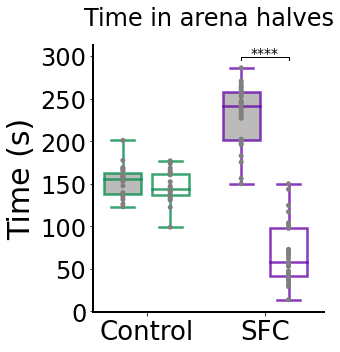

In [4]:
PROPS = {
    'boxprops':{'facecolor':'none', 'edgecolor':'mediumblue','alpha': 0.8},
    'medianprops':{'color':'cornflowerblue','alpha': 0.8},
    'whiskerprops':{'color':'cornflowerblue','alpha': 0.8},
    'capprops':{'color':'cornflowerblue','alpha': 0.8}
}

text_boxplot = ['','****']
colors = ["C7","C7"]
colors_boxplot = ['#078f4f', "#680aab"]
colors_boxplot_filling = ['#03f',"#c14"]
colors_boxplot_filling = ['#aba9a9',"#aba9a9"]


ax = sns.stripplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    x='control',
    palette=colors,
    jitter=0,
    dodge=True
)


locs = ["upper left"]
boxplot = sns.boxplot(
    data=newdf,
    hue='Experimental Condition',
    y='Left preference',
    x='control',
    palette=colors_boxplot,
    fliersize=0,
    linewidth=2.5,
    **PROPS
)

#plt.axhline(linewidth=2, color='lightgrey',ls='--')

data_ratio = 0.4016222222466667

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

#CHANGE BOXPLOT STYLE

box_patches = [patch for patch in boxplot.patches if type(patch) == matplotlib.patches.PathPatch]
if len(box_patches) == 0:  # in matplotlib older than 3.5, the boxes are stored in ax2.artists
    box_patches = boxplot.artists
    
num_patches = len(box_patches)
lines_per_boxplot = len(boxplot.lines) // num_patches


for i, patch in enumerate(box_patches):
    
    col = colors_boxplot[map_half(i,len(box_patches))]
    col_fill = colors_boxplot_filling[map_half(i,len(box_patches))]
    facecolor = col_fill if i%2==0 else 'None'
    patch.set_edgecolor(col)
    patch.set_facecolor(facecolor)
    
    for line in boxplot.lines[i * lines_per_boxplot: (i + 1) * lines_per_boxplot]:
        line.set_color(col)
        
        
#END CHANGE BOXPLOT STYLE

        

#handles, labels = ax.get_legend_handles_labels()
#l = plt.legend(handles[0:2], ["", ""],loc=2)

plt.legend([],[], frameon=False)

ax.set_xticklabels(['Cups','Social'], fontsize = 26)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

ax.set_xlabel("",fontsize=20)

###


ax.set_yticks(np.arange(0,301,50))

ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

plt.legend([],[], frameon=False)
ax.set_xticklabels(['Control','SFC'], fontsize = 26)
ax.set_xlabel("",fontsize=20)

ax.set_ylabel('Time (s)', fontsize = 30)

#ax.set_ylim([-0.5999,1.1])
ax.set_xlim([-0.45,1.5])

#significance(ax,0,data_ratio,newdf.loc[newdf['control']=='y']['Left preference'].max()+17,text=text_boxplot[0],offset=-4,whisker=4)
significance(ax,1,data_ratio,newdf.loc[newdf['control']=='n']['Left preference'].max()+17,text=text_boxplot[1],offset=-4,whisker=4)

plt.title("Time in arena halves", fontsize=24,y=1.05)


fig = ax.get_figure()

adjust_box_widths(fig, 0.8)
fig.set_size_inches(4.7,5)
ax.tick_params(axis='y', which='major', labelsize=24)


plt.tight_layout()
fig.tight_layout()
fig.savefig("Fig_AbsTimesHalves.jpg",dpi=500,bbox_inches='tight')
plt.savefig('Fig_AbsTimesHalves.eps', format='eps')

